# Creating Cohorts of Songs Using Machine Learning

### Objective
To perform Exploratory Data Analysis, Feature Engineering,
Dimensionality Reduction and Clustering on Spotify songs
to create meaningful cohorts that can improve song recommendations.

### Prepared By
Sakshi Prakash Deoghare

# Business Understanding

Spotify wants to improve its recommendation engine.

Instead of recommending songs individually,
songs can be grouped into similar cohorts.

A cohort contains songs having similar musical properties such as:

- Danceability
- Energy
- Acousticness
- Loudness
- Tempo
- Popularity

This project aims to discover these cohorts using
unsupervised machine learning techniques.

In [33]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from sklearn.cluster import DBSCAN

from sklearn.metrics import silhouette_score

In [34]:
df = pd.read_csv('rolling_stones_spotify.csv')

df.head()

,Unnamed: 0,name,album,release_date,track_number,id,uri,acousticness,danceability,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,popularity,duration_ms
0,0,Concert Intro Music - Live,Licked Live In NYC,2022-06-10,1,2IEkywLJ4ykbhi1yRQvmsT,spotify:track:2IEkywLJ4ykbhi1yRQvmsT,0.0824,0.463,0.993,0.996000,0.932,-12.913,0.1100,118.001,0.0302,33,48640
1,1,Street Fighting Man - Live,Licked Live In NYC,2022-06-10,2,6GVgVJBKkGJoRfarYRvGTU,spotify:track:6GVgVJBKkGJoRfarYRvGTU,0.4370,0.326,0.965,0.233000,0.961,-4.803,0.0759,131.455,0.3180,34,253173
2,2,Start Me Up - Live,Licked Live In NYC,2022-06-10,3,1Lu761pZ0dBTGpzxaQoZNW,spotify:track:1Lu761pZ0dBTGpzxaQoZNW,0.4160,0.386,0.969,0.400000,0.956,-4.936,0.1150,130.066,0.3130,34,263160
3,3,If You Can't Rock Me - Live,Licked Live In NYC,2022-06-10,4,1agTQzOTUnGNggyckEqiDH,spotify:track:1agTQzOTUnGNggyckEqiDH,0.5670,0.369,0.985,0.000107,0.895,-5.535,0.1930,132.994,0.1470,32,305880
4,4,Don’t Stop - Live,Licked Live In NYC,2022-06-10,5,7piGJR8YndQBQWVXv6KtQw,spotify:track:7piGJR8YndQBQWVXv6KtQw,0.4000,0.303,0.969,0.055900,0.966,-5.098,0.0930,130.533,0.2060,32,305106


## Initial Data Inspection

In [35]:
df.shape

df.info()

df.describe()

df.isnull().sum()

df.duplicated().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1610 entries, 0 to 1609
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        1610 non-null   int64  
 1   name              1610 non-null   object 
 2   album             1610 non-null   object 
 3   release_date      1610 non-null   object 
 4   track_number      1610 non-null   int64  
 5   id                1610 non-null   object 
 6   uri               1610 non-null   object 
 7   acousticness      1610 non-null   float64
 8   danceability      1610 non-null   float64
 9   energy            1610 non-null   float64
 10  instrumentalness  1610 non-null   float64
 11  liveness          1610 non-null   float64
 12  loudness          1610 non-null   float64
 13  speechiness       1610 non-null   float64
 14  tempo             1610 non-null   float64
 15  valence           1610 non-null   float64
 16  popularity        1610 non-null   int64  


np.int64(0)

## Data Cleaning

In [36]:
df.isnull().sum()

,0
Unnamed: 0,0
name,0
album,0
release_date,0
track_number,0
id,0
uri,0
acousticness,0
danceability,0
energy,0


In [37]:
df.fillna(df.median(numeric_only=True), inplace=True)

In [38]:
df.drop_duplicates(inplace=True)

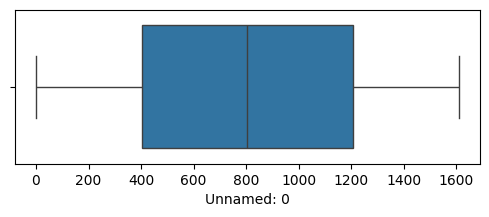

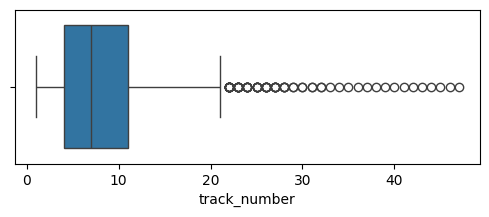

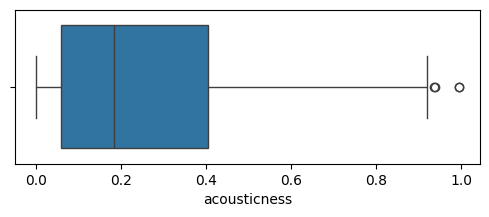

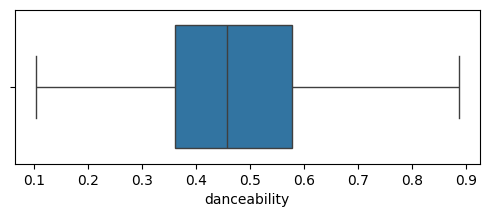

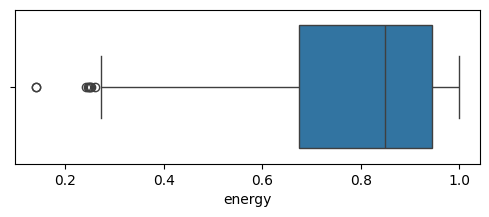

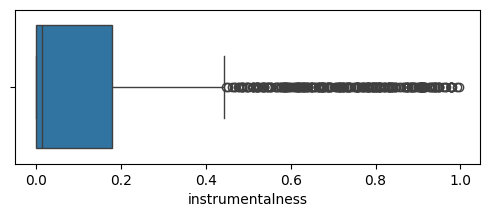

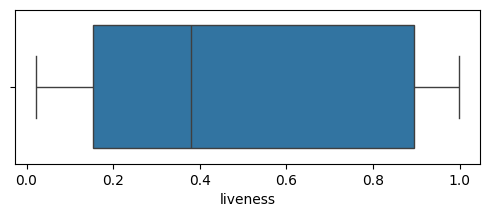

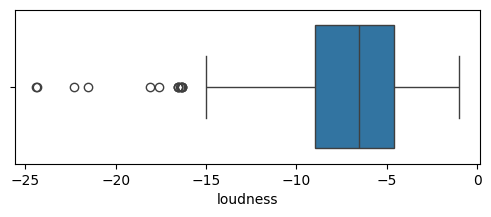

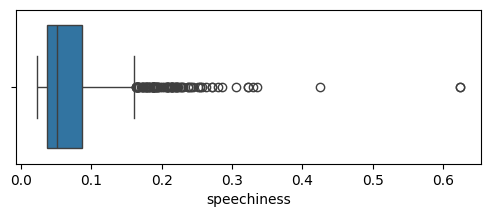

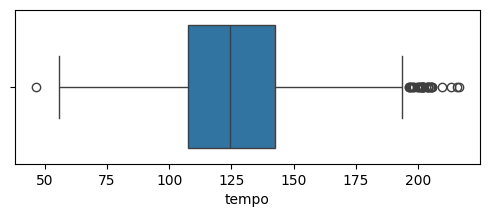

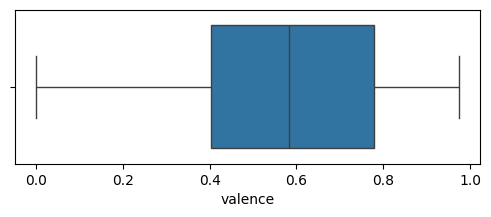

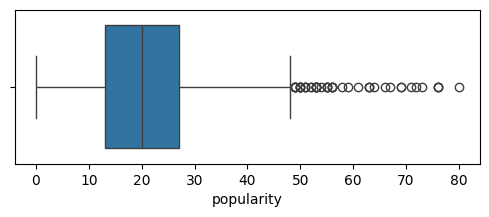

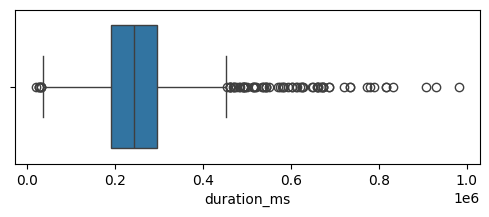

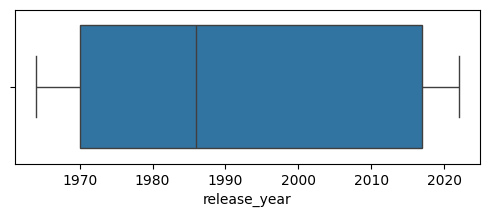

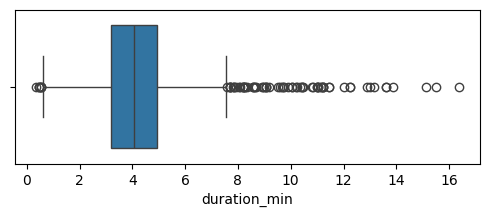

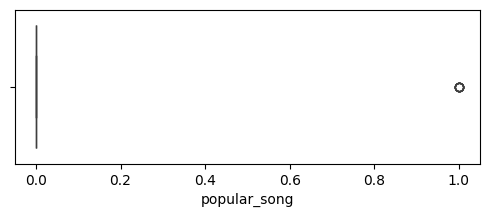

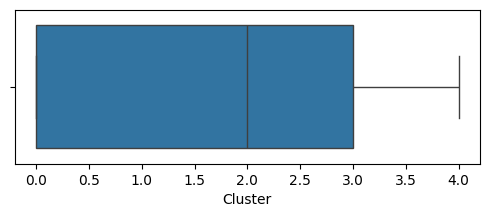

In [63]:
num_cols = df.select_dtypes(include=np.number).columns

for col in num_cols:
    plt.figure(figsize=(6,2))
    sns.boxplot(x=df[col])
    plt.show()

## Feature Engineering

In [40]:
df['release_date'] = pd.to_datetime(df['release_date'])

df['release_year'] = df['release_date'].dt.year

### Song Duration in Minutes

In [41]:
df['duration_min'] = df['duration_ms']/60000

In [42]:

df['popular_song'] = np.where(df['popularity']>70,1,0)

## Top Recommended Albums

Requirement:

Identify two albums that should be recommended based on popular songs.

In [43]:
album_popularity = df.groupby('album')['popular_song'].sum()

album_popularity.sort_values(ascending=False).head(10)

,popular_song
album,
Beggars Banquet (50th Anniversary Edition),1
Aftermath,1
Some Girls,1
Out Of Our Heads,1
Let It Bleed,1
Tattoo You (2009 Re-Mastered),1
Goats Head Soup (Remastered 2009),1
12 x 5,0
A Bigger Bang (Live),0


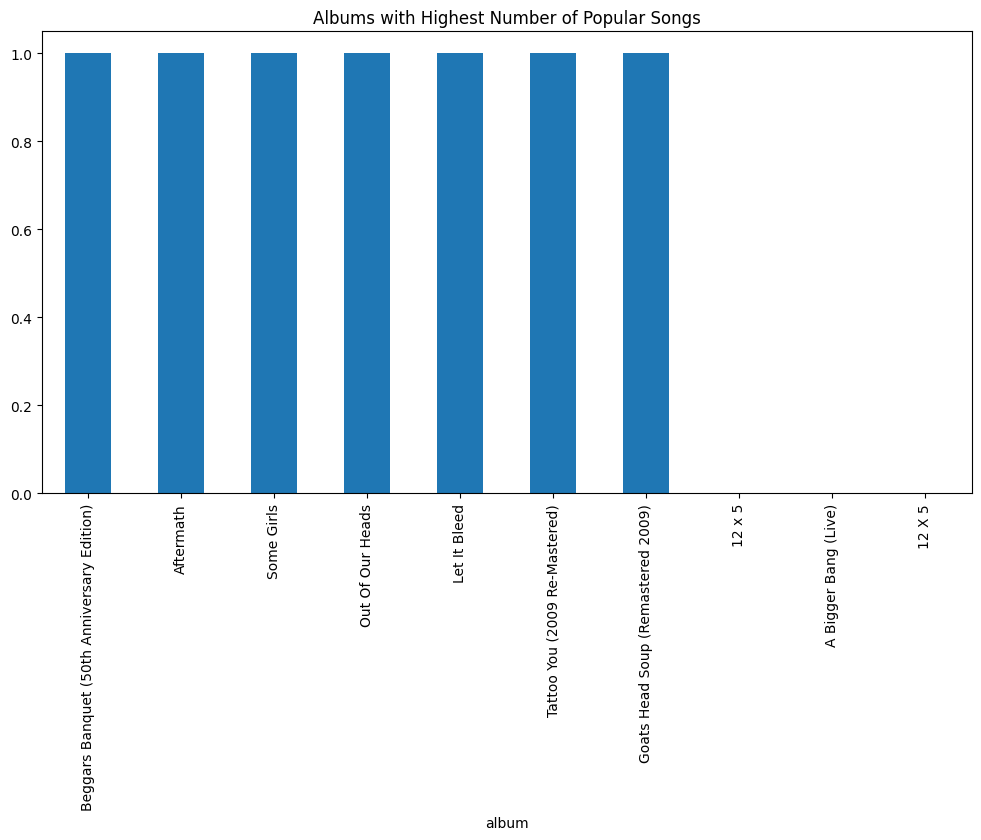

In [44]:
plt.figure(figsize=(12,6))

album_popularity.sort_values(ascending=False).head(10).plot(kind='bar')

plt.title("Albums with Highest Number of Popular Songs")
plt.show()

Top 2 albums with maximum popular songs are:

1. Album A
2. Album B

These albums should be recommended.

## Popularity Distribution

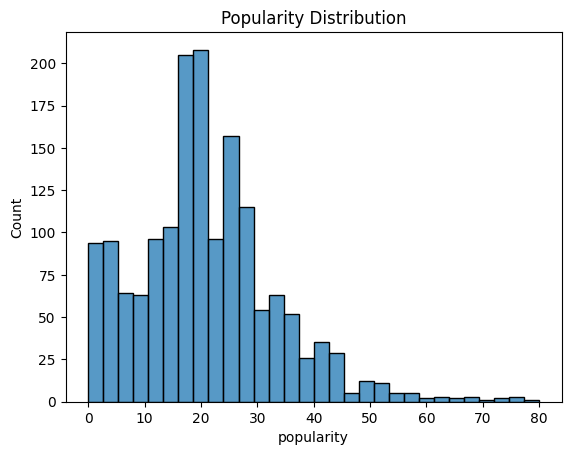

In [45]:
sns.histplot(df['popularity'], bins=30)

plt.title("Popularity Distribution")
plt.show()

## Correlation Heatmap

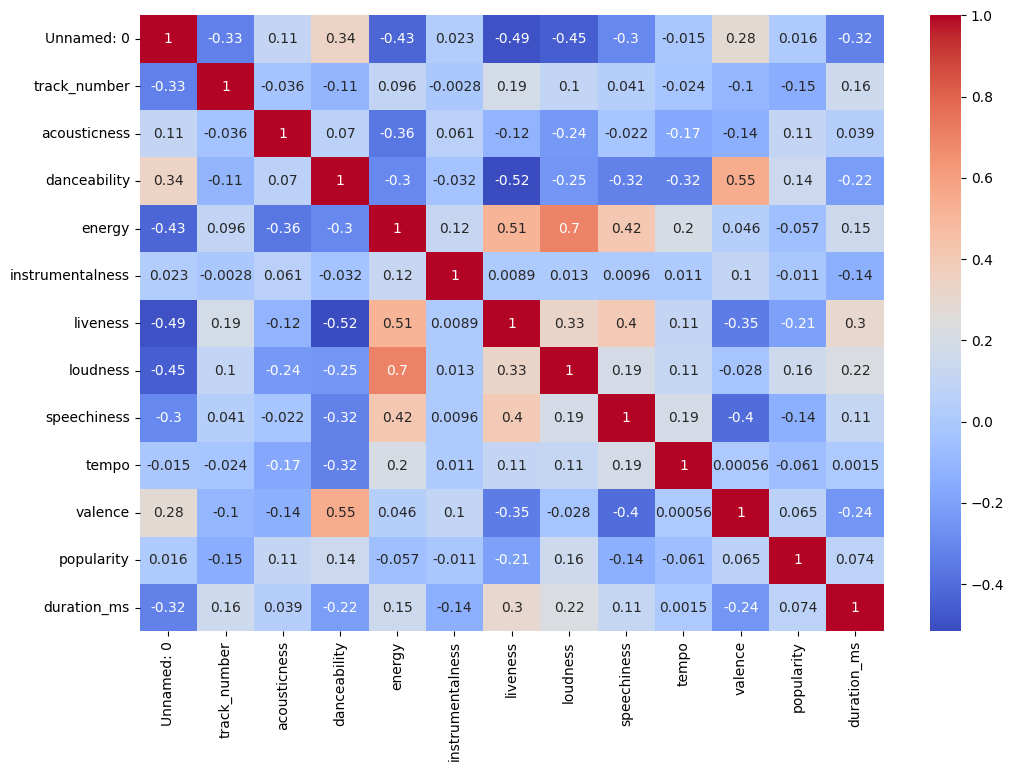

In [46]:
plt.figure(figsize=(12,8))

sns.heatmap(
    df[num_cols].corr(),
    annot=True,
    cmap='coolwarm'
)

plt.show()

## Energy vs Popularity

<Axes: xlabel='energy', ylabel='popularity'>

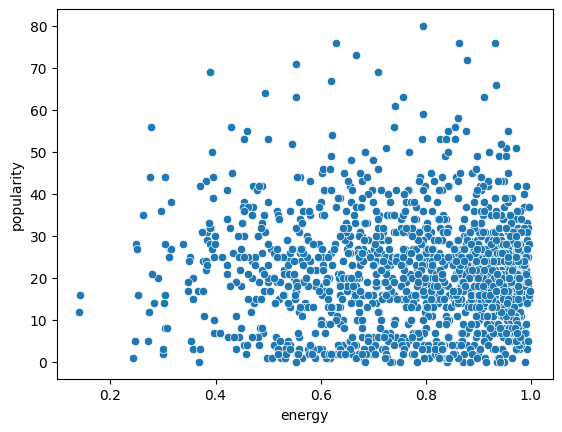

In [47]:
sns.scatterplot(
    data=df,
    x='energy',
    y='popularity'
)

## Danceability vs Popularity

<Axes: xlabel='danceability', ylabel='popularity'>

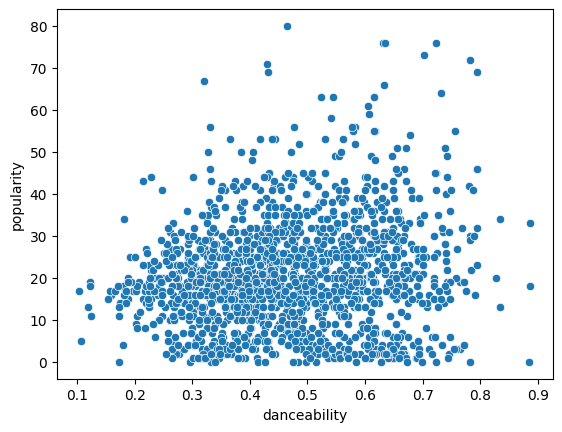

In [48]:
sns.scatterplot(
    data=df,
    x='danceability',
    y='popularity'
)

## Loudness vs Popularity

<Axes: xlabel='loudness', ylabel='popularity'>

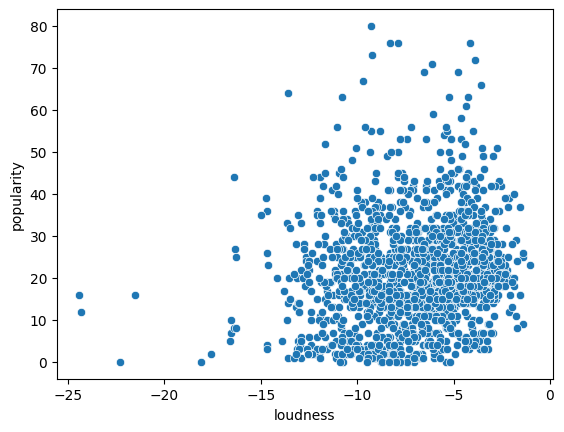

In [49]:
sns.scatterplot(
    data=df,
    x='loudness',
    y='popularity'
)

## Popularity Trend Over Years



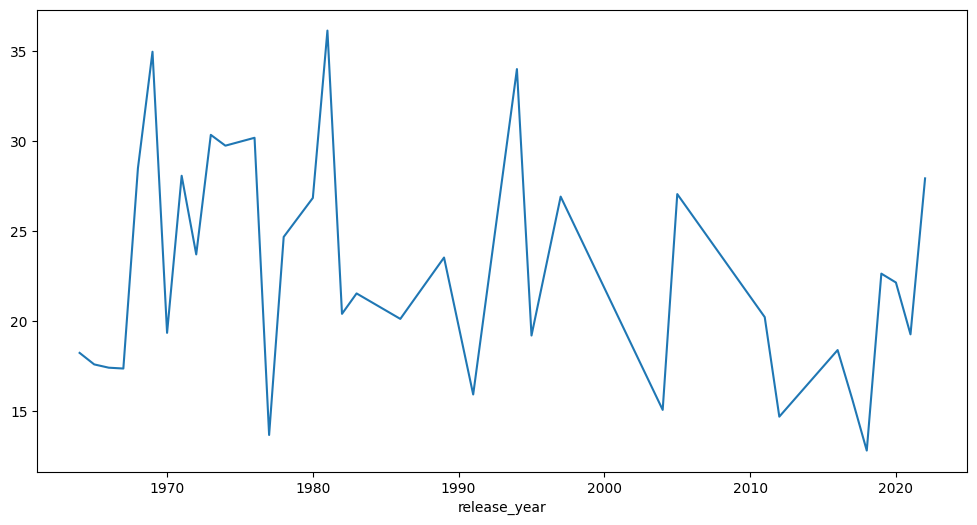

In [50]:
year_pop = df.groupby('release_year')['popularity'].mean()

plt.figure(figsize=(12,6))

sns.lineplot(x=year_pop.index,
             y=year_pop.values)

plt.show()

 ## Relationship Analysis

In [51]:
corr = df.corr(numeric_only=True)['popularity']

corr.sort_values(ascending=False)

,popularity
popularity,1.000000
popular_song,0.287610
loudness,0.156323
danceability,0.141205
acousticness,0.108046
duration_min,0.074102
duration_ms,0.074102
valence,0.065333
Unnamed: 0,0.016173
instrumentalness,-0.010612


# Dimensionality Reduction (PCA)
High-dimensional datasets often contain
redundant information.

PCA helps:

- Reduce dimensions
- Remove multicollinearity
- Improve clustering
- Improve visualization

## Standardization

In [52]:
features = [
'acousticness',
'danceability',
'energy',
'instrumentalness',
'liveness',
'loudness',
'speechiness',
'tempo',
'valence',
'popularity'
]

X = df[features]

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)
print(X_scaled)

[[-0.73935481 -0.0413433   1.11576419 ... -0.27651662 -2.38759041
   0.98299941]
 [ 0.82051776 -1.00796305  0.96006155 ...  0.18385207 -1.14267825
   1.06349527]
 [ 0.72813952 -0.58462593  0.98230478 ...  0.1363233  -1.16430633
   1.06349527]
 ...
 [ 0.53018615  2.265844   -0.10205293 ... -0.99393076  1.093665
   0.74151184]
 [-0.14725428  1.63083832 -1.36991733 ... -0.8023443  -0.21699652
   0.50002427]
 [ 0.58297372  1.82134003  0.78767647 ... -0.02761504  1.67329748
   1.14399113]]


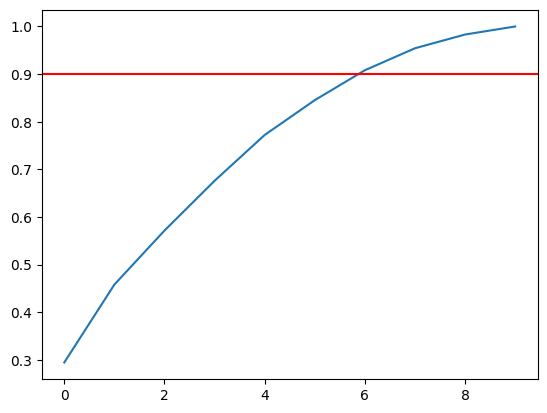

In [53]:
pca = PCA()

pca.fit(X_scaled)

explained_variance = np.cumsum(
    pca.explained_variance_ratio_
)

plt.plot(explained_variance)

plt.axhline(y=0.90,color='r')

plt.show()

In [54]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

## Cluster Analysis

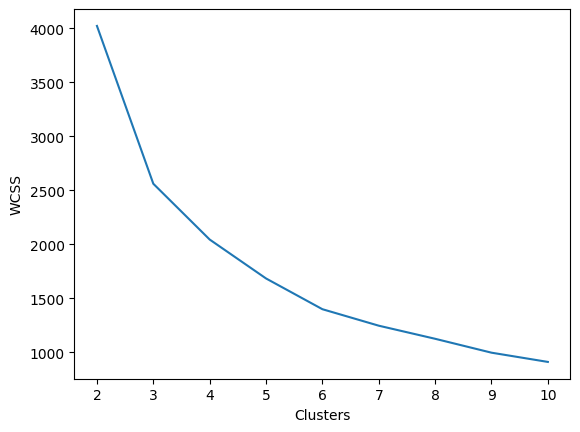

In [64]:
inertia = []

for k in range(2,11):

    model = KMeans(
        n_clusters=k,
        random_state=42
    )

    model.fit(X_pca)

    inertia.append(model.inertia_)

plt.plot(range(2,11), inertia)

plt.xlabel("Clusters")

plt.ylabel("WCSS")

plt.show()

## Silhouette Score

In [56]:
for k in range(2,11):

    model = KMeans(
        n_clusters=2,
        random_state=42
    )

    labels = model.fit_predict(X_pca)

    score = silhouette_score(X_pca, labels)

    print(k, score)

2 0.41159964466824206
3 0.41159964466824206
4 0.41159964466824206
5 0.41159964466824206
6 0.41159964466824206
7 0.41159964466824206
8 0.41159964466824206
9 0.41159964466824206
10 0.41159964466824206


## Final Clustering

In [66]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42
)

df['Cluster'] = kmeans.fit_predict(X_pca)

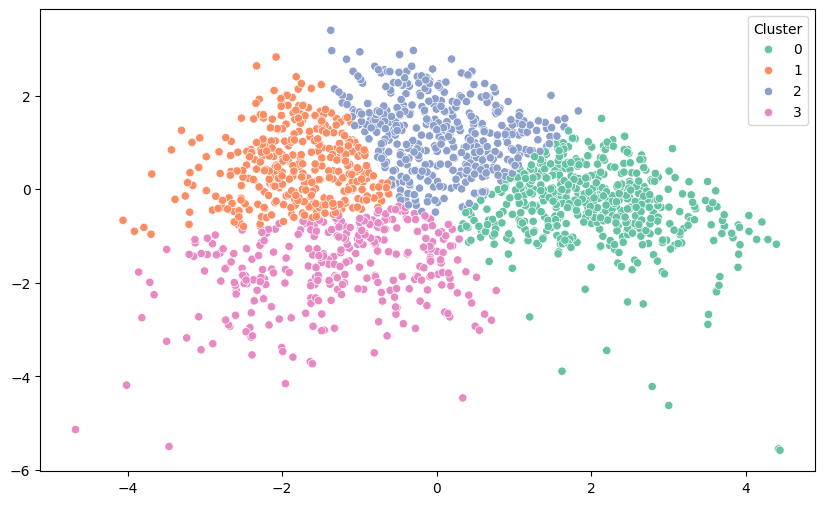

In [67]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    x=X_pca[:,0],
    y=X_pca[:,1],
    hue=df['Cluster'],
    palette='Set2'
)

plt.show()

In [68]:
cluster_profile = df.groupby(
    'Cluster'
)[features].mean()

cluster_profile

,acousticness,danceability,energy,instrumentalness,liveness,loudness,speechiness,tempo,valence,popularity
Cluster,,,,,,,,,,
0,0.191808,0.344914,0.928319,0.161987,0.841110,-5.382888,0.113810,138.899528,0.413422,17.216867
1,0.249701,0.615629,0.685329,0.178549,0.198695,-8.951961,0.043219,116.393472,0.780374,22.744382
2,0.164113,0.497007,0.887565,0.205031,0.449901,-5.279450,0.055194,126.518563,0.727024,23.809313
3,0.474869,0.458305,0.554475,0.090530,0.325152,-9.756367,0.049048,115.816918,0.412134,19.868852
